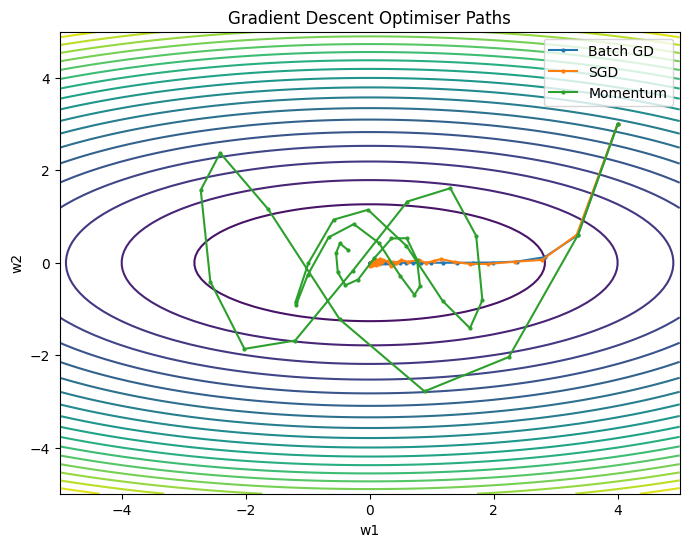

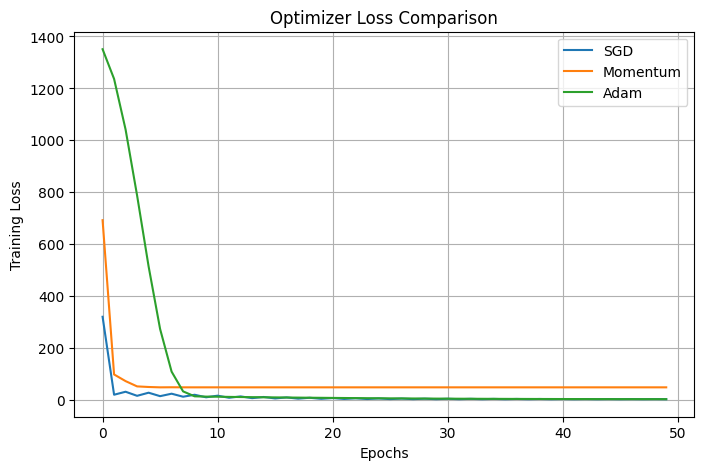

Learning Rate: 0.001 Final Loss: 681.8705
Learning Rate: 0.01 Final Loss: 6.8496
Learning Rate: 0.1 Final Loss: 3.997


In [5]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

# 1. Define loss function
def loss(w):
    return w[0]**2 + 5*w[1]**2

def gradient(w):
    return np.array([2*w[0], 10*w[1]])

# 2. Batch GD, SGD and Momentum
initial = np.array([4.0, 3.0])
lr = 0.08
steps = 40

paths = {}

# Batch Gradient Descent
w = initial.copy()
path = [w.copy()]
for _ in range(steps):
    w -= lr * gradient(w)
    path.append(w.copy())
paths["Batch GD"] = np.array(path)

# SGD using noisy gradients
w = initial.copy()
path = [w.copy()]
for _ in range(steps):
    noisy_grad = gradient(w) + np.random.normal(0, 0.5, 2)
    w -= lr * noisy_grad
    path.append(w.copy())
paths["SGD"] = np.array(path)

# Momentum
w = initial.copy()
velocity = np.zeros(2)
path = [w.copy()]
for _ in range(steps):
    velocity = 0.9 * velocity + lr * gradient(w)
    w -= velocity
    path.append(w.copy())
paths["Momentum"] = np.array(path)

# 3. Plot optimiser paths
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)
Z = X**2 + 5*Y**2

plt.figure(figsize=(8, 6))
plt.contour(X, Y, Z, levels=20)
for name, p in paths.items():
    plt.plot(p[:, 0], p[:, 1], marker="o", markersize=2, label=name)
plt.xlabel("w1")
plt.ylabel("w2")
plt.title("Gradient Descent Optimiser Paths")
plt.legend()
plt.show()

# 4. Create delivery-time dataset
X_data = np.random.rand(500, 4)
true_weights = np.array([10, 20, 5, 8])
y_data = X_data @ true_weights + 15 + np.random.normal(0, 2, 500)

X_train = X_data[:400]
y_train = y_data[:400]
X_test = X_data[400:]
y_test = y_data[400:]

# 5. Compare Keras optimisers
optimisers = {
    "SGD": keras.optimizers.SGD(learning_rate=0.01),
    "Momentum": keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9
    ),
    "Adam": keras.optimizers.Adam(learning_rate=0.01)
}

histories = {}

for name, opt in optimisers.items():
    model = keras.Sequential([
        keras.layers.Input(shape=(4,)),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1)
    ])

    model.compile(optimizer=opt, loss="mse")
    history = model.fit(
        X_train, y_train,
        epochs=50, batch_size=32,
        validation_data=(X_test, y_test),
        verbose=0
    )
    histories[name] = history.history["loss"]

# 6. Plot loss
plt.figure(figsize=(8, 5))
for name, values in histories.items():
    plt.plot(values, label=name)
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Optimizer Loss Comparison")
plt.legend()
plt.grid()
plt.show()

# 7. Learning rate comparison
for rate in [0.001, 0.01, 0.1]:
    model = keras.Sequential([
        keras.layers.Input(shape=(4,)),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1)
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(rate),
        loss="mse"
    )
    h = model.fit(X_train, y_train, epochs=30, verbose=0)
    print("Learning Rate:", rate,
          "Final Loss:", round(h.history["loss"][-1], 4))
